## Car Price Prediction Using Linear Regression

## Step 1: Data Understanding & Preprocessing
    •	Load and explore the dataset.
    •	Check for missing values and handle them.
    •	Convert categorical variables (Fuel_Type, Mileage, Airbags) into numerical format.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Sahil\Machine Learning\repository\Linear Regrassion\car_price_prediction_dataset.csv")
print(df.head())

   ID  Price   Levy Manufacturer     Model  Prod. year   Category  \
0   1  20893  723.0          BMW        X5        2016    Minivan   
1   2   9261  886.0          Kia  Sportage        2011      Sedan   
2   3   4943  747.0        Lexus        RX        2003  Hatchback   
3   4  21334  920.0          BMW        X5        2015        SUV   
4   5   9622  977.0      Hyundai       i30        2013        SUV   

  Leather interior Fuel type  Engine volume  Mileage  Cylinders Gear box type  \
0               No    Diesel            1.8    89881          4        Manual   
1               No    Petrol            3.5   203312          4        Manual   
2              Yes    Diesel            1.6   278279          4     Automatic   
3              Yes    Hybrid            2.5   139600          6        Manual   
4               No    Petrol            1.8   189408          4     Automatic   

  Drive wheels   Doors       Wheel  Color  Airbags  
0         Rear  04-May  Left wheel   Blue    

In [5]:
df.shape

(600, 18)

In [6]:
df.columns.tolist()

['ID',
 'Price',
 'Levy',
 'Manufacturer',
 'Model',
 'Prod. year',
 'Category',
 'Leather interior',
 'Fuel type',
 'Engine volume',
 'Mileage',
 'Cylinders',
 'Gear box type',
 'Drive wheels',
 'Doors',
 'Wheel',
 'Color',
 'Airbags']

##  Data Understanding

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                600 non-null    int64  
 1   Price             600 non-null    int64  
 2   Levy              596 non-null    float64
 3   Manufacturer      600 non-null    str    
 4   Model             600 non-null    str    
 5   Prod. year        600 non-null    int64  
 6   Category          600 non-null    str    
 7   Leather interior  596 non-null    str    
 8   Fuel type         596 non-null    str    
 9   Engine volume     600 non-null    float64
 10  Mileage           600 non-null    int64  
 11  Cylinders         600 non-null    int64  
 12  Gear box type     600 non-null    str    
 13  Drive wheels      600 non-null    str    
 14  Doors             600 non-null    str    
 15  Wheel             600 non-null    str    
 16  Color             596 non-null    str    
 17  Airbags 

In [8]:
df.describe(include="all")

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
count,600.000000,600.000000,596.000000,600,600,600.000000,600,596,596,600.000000,600.000000,600.000000,600,600,600,600,596,600.000000
unique,NaN,NaN,NaN,12,48,NaN,7,2,5,NaN,NaN,NaN,4,3,3,2,8,NaN
top,NaN,NaN,NaN,Kia,ES,NaN,Sedan,Yes,Petrol,NaN,NaN,NaN,Automatic,Front,04-May,Left wheel,Silver,NaN
freq,NaN,NaN,NaN,62,19,NaN,170,365,346,NaN,NaN,NaN,344,382,489,562,90,NaN
mean,300.500000,12626.571667,628.184564,NaN,NaN,2012.011667,NaN,NaN,NaN,2.186000,173592.038333,4.696667,NaN,NaN,NaN,NaN,NaN,6.520000
std,173.349358,7193.155997,355.878942,NaN,NaN,7.354705,NaN,NaN,NaN,0.915296,94376.303929,1.353159,NaN,NaN,NaN,NaN,NaN,2.815934
min,1.000000,1200.000000,0.000000,NaN,NaN,2000.000000,NaN,NaN,NaN,1.000000,0.000000,4.000000,NaN,NaN,NaN,NaN,NaN,2.000000
25%,150.750000,7001.250000,368.250000,NaN,NaN,2005.000000,NaN,NaN,NaN,1.500000,95429.250000,4.000000,NaN,NaN,NaN,NaN,NaN,4.000000
50%,300.500000,12523.500000,613.500000,NaN,NaN,2012.000000,NaN,NaN,NaN,2.000000,172032.500000,4.000000,NaN,NaN,NaN,NaN,NaN,6.000000
75%,450.250000,17072.500000,872.250000,NaN,NaN,2018.000000,NaN,NaN,NaN,3.000000,250755.500000,4.000000,NaN,NaN,NaN,NaN,NaN,8.000000


In [9]:
df.isna().sum()

ID                  0
Price               0
Levy                4
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    4
Fuel type           4
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               4
Airbags             0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

##  Data Preprocessing

In [13]:

print(df.isnull().sum())

ID                  0
Price               0
Levy                4
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    4
Fuel type           4
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               4
Airbags             0
dtype: int64


In [14]:

df = df.drop_duplicates().copy()

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df = df.dropna(subset=["Price"]).copy()


numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in numerical_cols:
    if col != "Price":
        df[col] = df[col].fillna(df[col].median())


for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)



print(df.isnull().sum())

print(df.shape)


ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64
(600, 18)


C:\Users\mulik\AppData\Local\Temp\ipykernel_19436\1925647204.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


## Step 2: Exploratory Data Analysis (EDA)

    -Generate descriptive statistics.
    -Create visualizations (histograms, scatter plots, boxplots, correlation heatmap).
    -Identify relationships between independent variables and selling price.


In [15]:
df.describe()

,ID,Price,Levy,Prod. year,Engine volume,Mileage,Cylinders,Airbags
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,12626.571667,628.086667,2012.011667,2.186000,173592.038333,4.696667,6.520000
std,173.349358,7193.155997,354.690724,7.354705,0.915296,94376.303929,1.353159,2.815934
min,1.000000,1200.000000,0.000000,2000.000000,1.000000,0.000000,4.000000,2.000000
25%,150.750000,7001.250000,369.000000,2005.000000,1.500000,95429.250000,4.000000,4.000000
50%,300.500000,12523.500000,613.500000,2012.000000,2.000000,172032.500000,4.000000,6.000000
75%,450.250000,17072.500000,867.250000,2018.000000,3.000000,250755.500000,4.000000,8.000000
max,600.000000,38363.000000,1812.000000,2024.000000,4.000000,352717.000000,8.000000,12.000000


In [16]:
df.describe(include="object")

C:\Users\mulik\AppData\Local\Temp\ipykernel_19436\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Manufacturer,Model,Category,Leather interior,Fuel type,Gear box type,Drive wheels,Doors,Wheel,Color
count,600,600,600,600,600,600,600,600,600,600
unique,12,48,7,2,5,4,3,3,2,8
top,Kia,ES,Sedan,Yes,Petrol,Automatic,Front,04-May,Left wheel,Silver
freq,62,19,170,369,350,344,382,489,562,94


**Histogram**

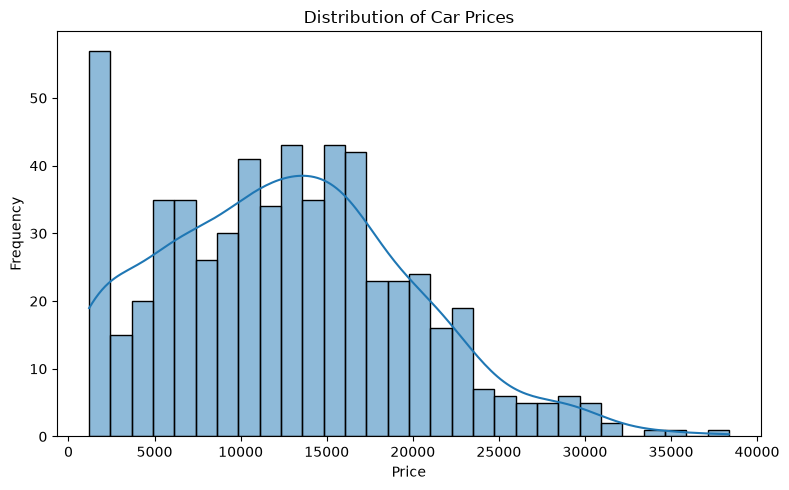

In [17]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Price", bins=30, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**Correlation Heatmap**

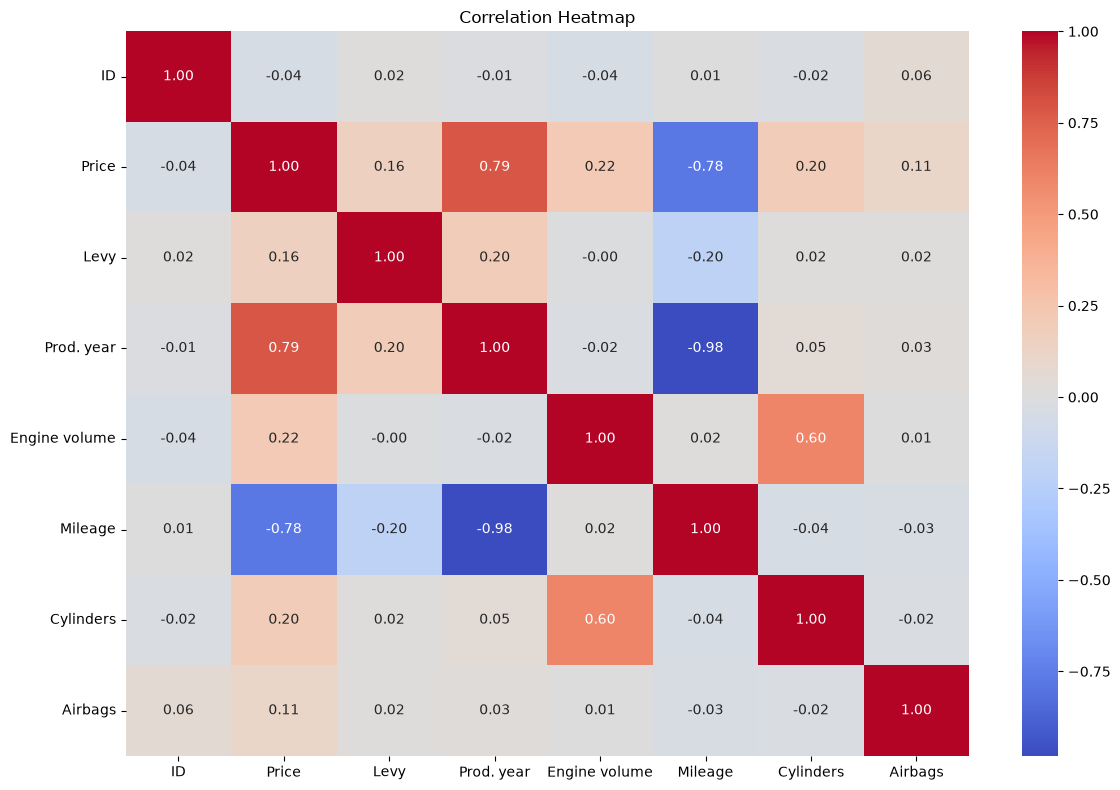

In [18]:

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


**Scatter plot**

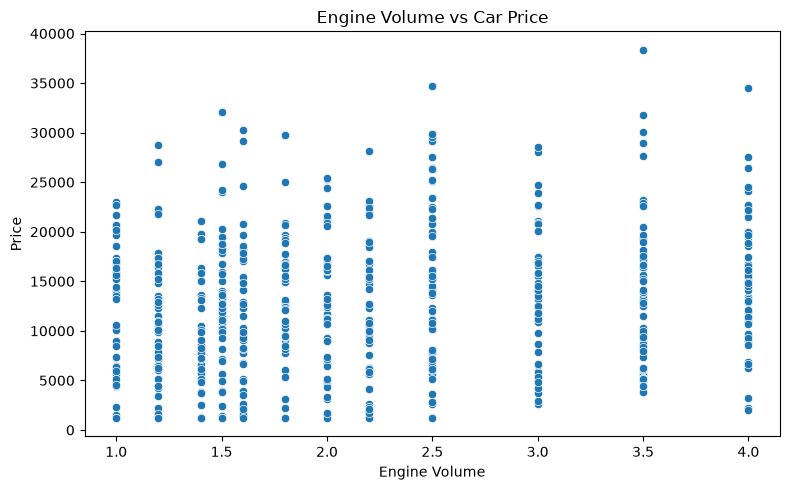

In [19]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Engine volume", y="Price")

plt.title("Engine Volume vs Car Price")
plt.xlabel("Engine Volume")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


**Box plot**

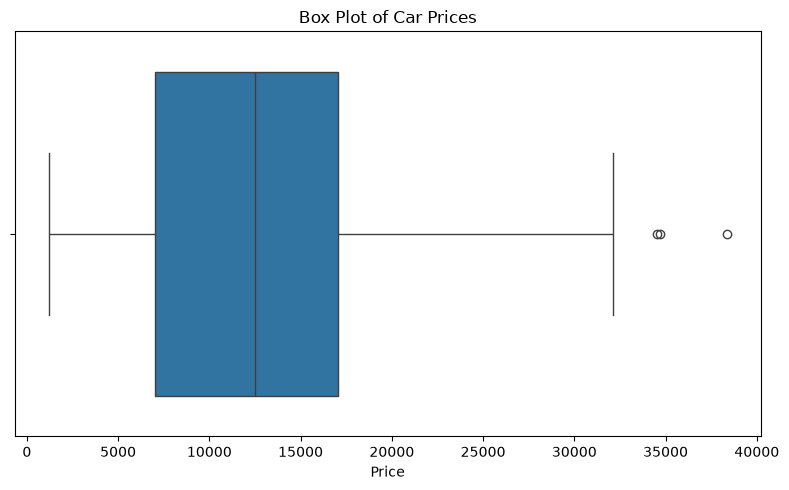

In [20]:

plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Price"])

plt.title("Box Plot of Car Prices")
plt.xlabel("Price")
plt.tight_layout()
plt.show()


## Step 3: Model Development

    •	Split dataset into train and test sets.
    •	Build a Linear Regression model to predict selling price.
    •	Train the model on training data.
    •	Test the model on unseen test data


**Separate Features and Target**

In [21]:

# Remove ID because it is only an identifier
X = df.drop(columns=["Price", "ID"], errors="ignore")

y = df["Price"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print(X.head())


Features Shape: (600, 90)
Target Shape: (600,)
    Levy  Prod. year  Engine volume  Mileage  Cylinders  Airbags  \
0  723.0        2016            1.8    89881          4       12   
1  886.0        2011            3.5   203312          4        4   
2  747.0        2003            1.6   278279          4        4   
3  920.0        2015            2.5   139600          6        8   
4  977.0        2013            1.8   189408          4        6   

   Manufacturer_BMW  Manufacturer_Chevrolet  Manufacturer_Ford  \
0                 1                       0                  0   
1                 0                       0                  0   
2                 0                       0                  0   
3                 1                       0                  0   
4                 0                       0                  0   

   Manufacturer_Honda  ...  Doors_04-May  Doors_>5  Wheel_Right-hand drive  \
0                   0  ...             1         0                   

**Train-Test Split**

In [24]:

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (480, 90)
Testing Features: (120, 90)
Training Target: (480,)
Testing Target: (120,)


**Build and Train Linear Regression**

In [31]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


**Predict Car Prices**

In [32]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": np.round(y_pred, 2)
})

print("Actual vs Predicted Prices:")
print(comparison.head(10))

Actual vs Predicted Prices:
   Actual Price  Predicted Price
0         12054         11927.59
1          9919         15077.33
2          1200           583.51
3         15625         16061.06
4         20083         20334.07
5         16170         18995.91
6         14043         12807.96
7          1200         -3073.82
8         19244         20826.62
9         15789         17082.62


## Step 4: Model Evaluation
    •	Calculate evaluation metrics:
    o	R² Score
    o	Mean Absolute Error (MAE)
    o	Mean Squared Error (MSE)
    o	Root Mean Squared Error (RMSE)


In [34]:

import numpy as np

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)


In [37]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))


R2 Score: 0.8548
MAE: 2085.46
MSE: 7038903.32
RMSE: 2653.09
